# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M. 
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

#### **I. Synthetic data interpolation.** 
![Plot of the different interpolation methods on a sine function](synthetic_data_interpolation.jpg) <img src="../Claire/Exercise 9/synthetic_data_interpolation.jpg" width=45%>
***Figure 1** shows the plot comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.*

#### **II. Real-world data reconstruction.** 
![Interpolation of Real-world Data](interp_real_world_data.jpg) <img src="../Claire/Exercise 9/interp_real_world_data.jpg" width=45%>
***Figure 2.e** shows the plot of the reconstruction of the Dow Jones time-series dataset at different sampling fractions.*

![Different Interpolation Methods on Sampled Real-world Data](interp_sampled_real_world_data.jpg) <img src="../Claire/Exercise 9/interp_sampled_real_world_data.jpg" width=45%>
***Figure 3** shows the plot of the reconstruction of the 50% sampled Dow Jones time-series dataset using different interpolation methods.*


### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

For the synthetic sine data, the interpolators differ mainly in smoothness and in how well they follow the function’s curvature. Nearest interpolation produces a staircase because it copies the closest sampled value, and it has the largest error. Linear interpolation is continuous but forms corners at each sample, and it underestimates the peak and trough because straight segments cannot follow the curvature. Quadratic and cubic interpolation fit smooth piecewise polynomials through the samples, tracking the sine closely even with only 15 random samples. Based on the computed RMSE values, cubic interpolation had the lowest error, followed by quadratic. This is consistent with the cubic spline’s continuous slope and curvature at each sample, which suits a smooth function. Therefore, cubic interpolation reproduces the underlying function most accurately. This result holds because sine is a smooth, noise-free function, but it may not hold for noisy real-world data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

As the sampling fraction decreases from 50% to 5%, the reconstruction quality of the Dow Jones series steadily worsens. At 50% and 30%, the reconstructed curve follows the original closely and preserves most peaks and dips. At 10% and 5%, the gaps between samples become wide, so short-term fluctuations are lost and only the broad trend survives. With nearest interpolation, this appears as wider flat steps and abrupt jumps, a blocky artifact that misses the local highs and lows between samples. Because the samples are random, uneven spacing also makes some regions much worse than others. The main limitation is that interpolation can only use the information in the samples. It cannot recover detail that falls between them, and it cannot predict values outside the sampled range. Including the first and last points avoids truncating the ends, but extrapolating beyond the data would be unreliable.

### Other comments
- I just followed the instructions from previous exercises to limit answers per questions to 150 words.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
def f(x):
    return np.sin(x)

# Dense grid for the "true" curve and for evaluating reconstructions
x_data = np.linspace(0, 2 * np.pi, 1000)
y_data = f(x_data)

# Generating random samples, included endpoints
n_samples = 15
x_samples = np.sort(np.concatenate(([0, 2 * np.pi], rng.uniform(0, 2 * np.pi, n_samples - 2))))
y_samples = f(x_samples)

# Setting-up interpolation methods
interp_linear = interpolate.interp1d(x_samples, y_samples, kind='linear')
interp_cubic = interpolate.interp1d(x_samples, y_samples, kind='cubic')
interp_nearest = interpolate.interp1d(x_samples, y_samples, kind='nearest')
interp_quadratic = interpolate.interp1d(x_samples, y_samples, kind='quadratic')

y_lin = interp_linear(x_data)
y_cubic = interp_cubic(x_data)
y_nearest = interp_nearest(x_data)
y_quadratic = interp_quadratic(x_data)

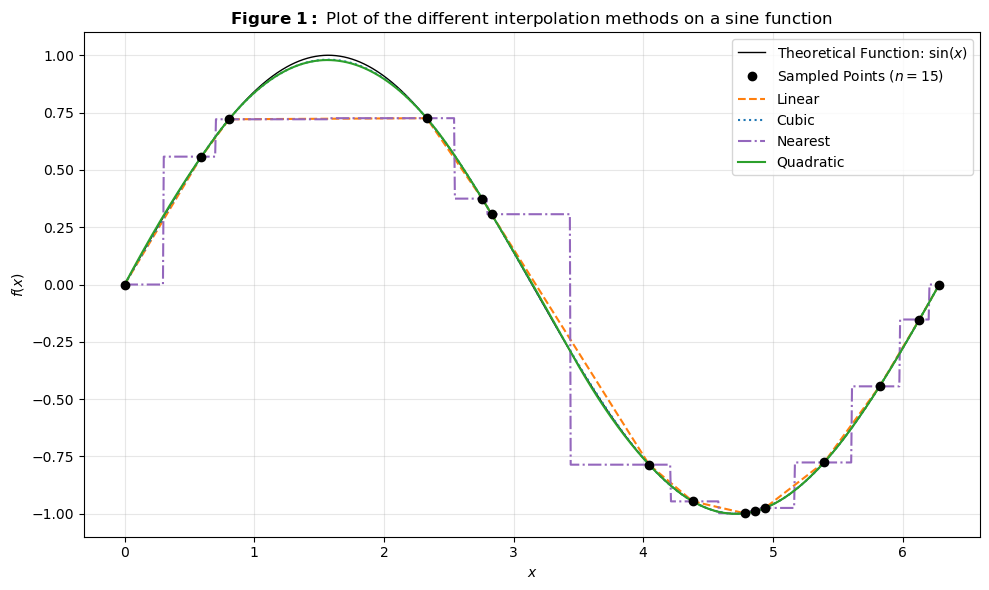

In [11]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(x_data, y_data, 'k-', label=r'Theoretical Function: $\sin(x)$', alpha=1.0, lw=1)
ax.plot(x_samples, y_samples, 'ko', label=f'Sampled Points ($n = {n_samples}$)', zorder=5)
ax.plot(x_data, y_lin, '--', label='Linear', color='tab:orange', alpha=1.0)
ax.plot(x_data, y_cubic, ':', label='Cubic', color='tab:blue', alpha=1.0)
ax.plot(x_data, y_nearest, '-.', label='Nearest', color='tab:purple', alpha=1.0)
ax.plot(x_data, y_quadratic, '-', label='Quadratic', color='tab:green', alpha=1.0)

ax.set_title(r'$\bf{Figure\ 1:}$ Plot of the different interpolation methods on a sine function')
ax.set_xlabel('$x$')
ax.set_ylabel('$f(x)$')
ax.legend(loc='best')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('synthetic_data_interpolation.jpg', dpi=150)
plt.show()

The report discussion asks which method reproduces the synthetic function most accurately. In Figure 1, the cubic and quadratic interpolations are visually very close to each other, so we compute the root mean squared error (RMSE) of each method to compare them quantitatively.

In [4]:
for name, y_rec in [('Linear', y_lin), ('Cubic', y_cubic), ('Nearest', y_nearest), ('Quadratic', y_quadratic)]:
    print(f"{name}: RMSE = {np.sqrt(np.mean((y_rec - y_data)**2)):.4f}")

Linear: RMSE = 0.1006
Cubic: RMSE = 0.0064
Nearest: RMSE = 0.1818
Quadratic: RMSE = 0.0072


Here, we can now say that it is the **cubic interpolation** that reproduces the function most accurately. 

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [5]:
filepath = "rawdatafile.txt"

In [6]:
# Loading the data 
RealRawData = np.loadtxt(filepath)
n = len(RealRawData)
x_fulldata= np.arange(n) # To arrange in chronological order
y_fulldata = RealRawData

In [7]:
# Randomly selecting the sample indices once so every figure in this problem uses the same samples
sampling_fractions = [0.50, 0.30, 0.10, 0.05]
sample_dict = {}

for frac in sampling_fractions:
    num_samples = int(len(RealRawData) * frac)

    inner_indices = rng.choice(np.arange(1, n-1), size=num_samples -2, replace=False)
    sample_dict[frac] = np.sort(np.concatenate(([0, len(RealRawData) -1], inner_indices)))

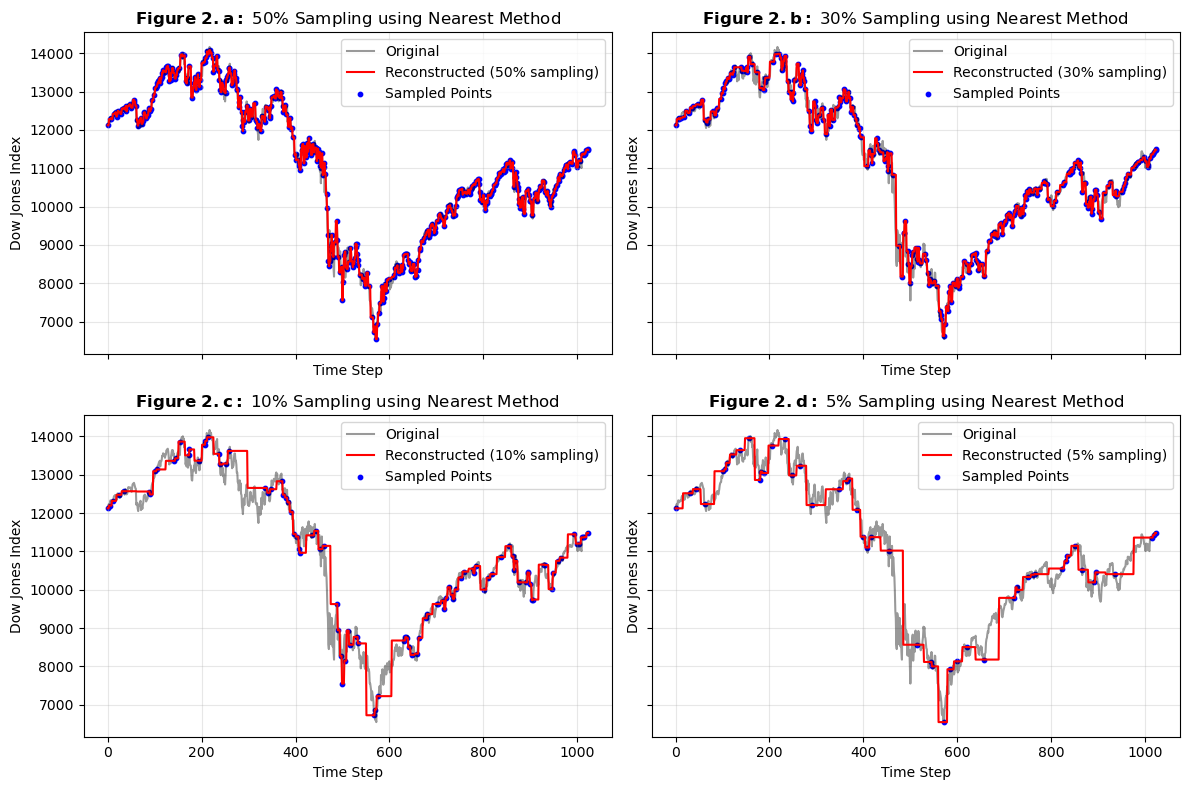

In [8]:
sampling_fractions = [0.50, 0.30, 0.10, 0.05]
label = ['a', 'b', 'c', 'd']
kind = 'nearest' # Change according to method preference 

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)

for frac, ax, lbl in zip(sampling_fractions, axes.flatten(), label):
    sample_indices = sample_dict[frac]

    x_sampled = x_fulldata[sample_indices]
    y_sampled = y_fulldata[sample_indices]

    # Reconstructing using interpolation functions
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=kind)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the comparison 
    ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)
    ax.plot(x_interp, y_interp, label=f'Reconstructed ({int(frac*100)}% sampling)', color='red')
    ax.scatter(x_sampled, y_sampled, color='blue', s=10, label='Sampled Points')
    ax.set_title(fr'$\bf{{Figure\ 2.{lbl}:}}$ {int(frac*100)}% Sampling using {kind.capitalize()} Method') 
    ax.set_xlabel('Time Step')
    ax.set_ylabel('Dow Jones Index')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

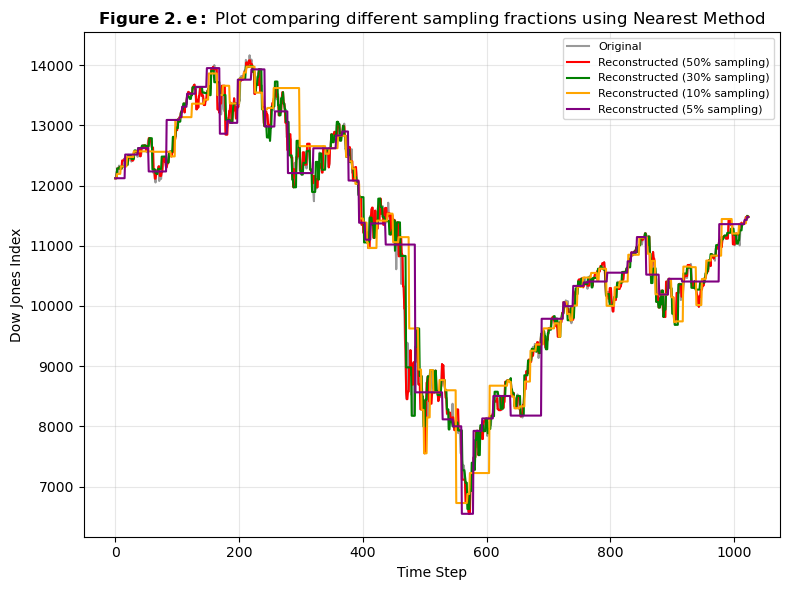

In [9]:
# Overlaying the reconstructed curves in a single, unified plot
sampling_fractions = [0.50, 0.30, 0.10, 0.05]
colors = ['red', 'green', 'orange', 'purple']
kind = 'nearest' # Change according to method preference 

# Plotting
fig, ax = plt.subplots(figsize=(8,6))

# Plotting original dataset
ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)

for frac, color in zip(sampling_fractions, colors):
    sample_indices = sample_dict[frac]
    
    x_sampled = x_fulldata[sample_indices]
    y_sampled = y_fulldata[sample_indices]

    # Reconstructing using interpolation functions
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=kind)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the reconstructed fraction on the same axis
    ax.plot(x_interp, y_interp, label=f'Reconstructed ({int(frac*100)}% sampling)', color=color)

ax.set_title(fr'$\bf{{Figure\ 2.e:}}$ Plot comparing different sampling fractions using {kind.capitalize()} Method')
ax.set_xlabel('Time Step')
ax.set_ylabel('Dow Jones Index')
ax.legend(loc='best', fontsize=8)
ax.grid(True, alpha=0.3)
    
plt.tight_layout()
plt.savefig('interp_real_world_data.jpg', dpi=150)
plt.show()

**NOTE:** Sampled points are not shown in Figure 2.e because each sampling fraction is its own random subset, so the four reconstructed curves have four different sets of sampled points. To see the sampled points for each fraction, refer to Figures 2.a-d.

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

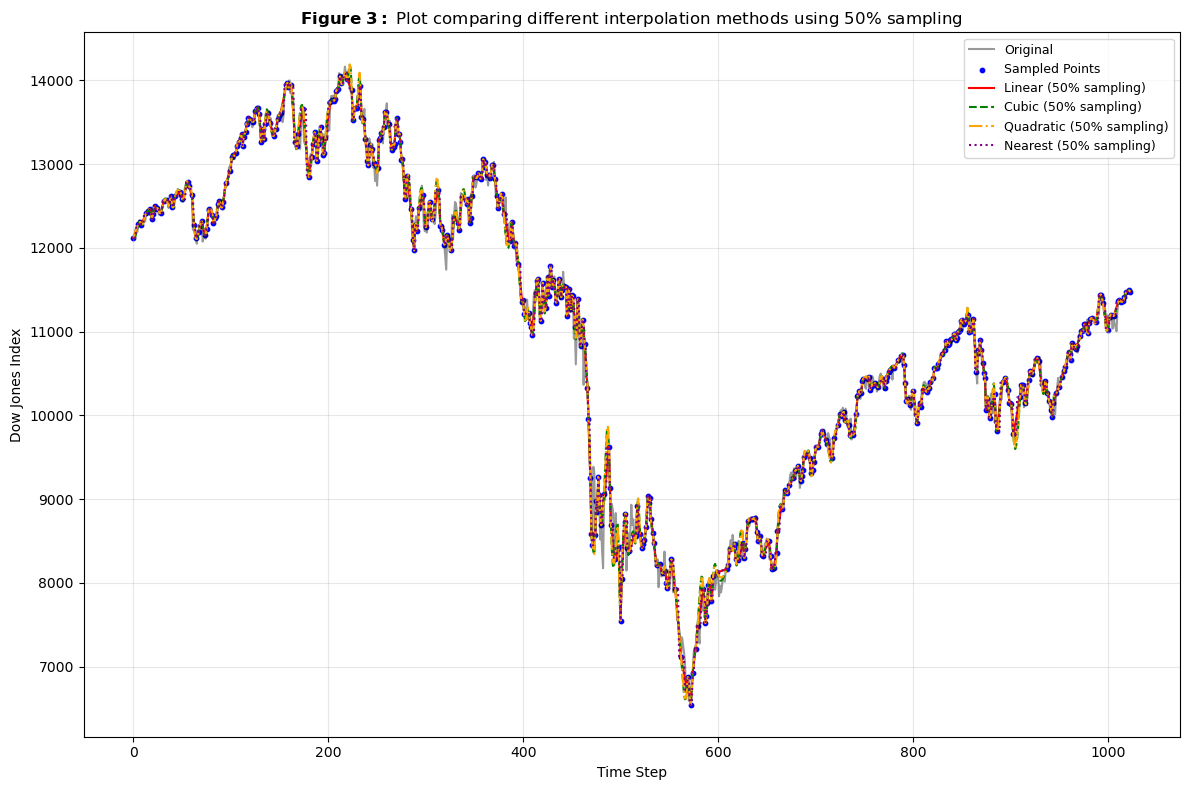

In [10]:
sampling_fraction = 0.50
kinds = ['linear', 'cubic', 'quadratic', 'nearest']
colors = ['red', 'green', 'orange', 'purple']
linestyles = ['-', '--', '-.', ':']

fig, ax = plt.subplots(figsize=(12,8))

# Calculating sampled indices and variables 
sample_indices = sample_dict[sampling_fraction] # Applying the random selection of samples in Problem 2 to stay consistent
    
x_sampled = x_fulldata[sample_indices]
y_sampled = y_fulldata[sample_indices]

# Plotting original dataset and scatter points
ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)
ax.scatter(x_sampled, y_sampled, color='blue', s=10, label='Sampled Points')

for k, color, ls in zip(kinds, colors, linestyles):
    # Reconstructing using interpolation methods 
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=k)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the reconstructed fraction on the same axis 
    ax.plot(x_interp, y_interp, label=f'{k.capitalize()} ({int(sampling_fraction*100)}% sampling)', color=color, linestyle=ls, linewidth=1.5)

ax.set_title(fr'$\bf{{Figure\ 3:}}$ Plot comparing different interpolation methods using {int(sampling_fraction*100)}% sampling')
ax.set_xlabel('Time Step')
ax.set_ylabel('Dow Jones Index')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('interp_sampled_real_world_data.jpg', dpi=150)
plt.show()

### Problem  code summary

My code compares different interpolation methods (linear, cubic, quadratic, nearest) by reconstructing a function from a subset of its points. In Problem 1, I sampled a sine function at random points and checked each interp1d method against the theoretical function. In Problems 2 and 3, I randomly sampled the Dow Jones data at 50%, 30%, 10%, and 5%, always including the first and last points, then compared the sampling fractions using one method (Problem 2) and the different methods using one sampling fraction (Problem 3); I used interp1d because it handles all the methods the same way, and I also seeded the random generator so the results are reproducible.